In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from churn.loader import DataLoader
from scipy import stats

%matplotlib inline

df = DataLoader(data_path="../data/raw/dataset.csv").load()
resumo = pd.concat([df.isna().sum(), df.mean(numeric_only=True)], axis=1)
print(f"""
Dataset carregado
============================================
Linhas: {df.shape[0]}
Colunas: {df.shape[1]} - {df.columns}
============================================
Valores nulos x média por coluna:
{resumo}
Valores nulos no dataset: {df.isna().sum().sum()}
""")
df.head(10)


Dataset carregado
Linhas: 7043
Colunas: 21 - Index(['customerID', 'gender', 'SeniorCitizen', 'MultipleLines', 'Partner',
       'Dependents', 'tenure', 'PhoneService', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')
Valores nulos x média por coluna:
                  0          1
customerID        0        NaN
gender            0        NaN
SeniorCitizen     0   0.162147
MultipleLines     0        NaN
Partner           0        NaN
Dependents        0        NaN
tenure            0  32.371149
PhoneService      0        NaN
InternetService   0        NaN
OnlineSecurity    0        NaN
OnlineBackup      0        NaN
DeviceProtection  0        NaN
TechSupport       0        NaN
StreamingTV       0        NaN
StreamingMovies   0        NaN
Contract          0        NaN
PaperlessBillin

,customerID,gender,SeniorCitizen,MultipleLines,Partner,Dependents,tenure,PhoneService,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,No phone service,Yes,No,1,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,No,34,Yes,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,No,2,Yes,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No phone service,No,No,45,No,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,No,2,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,Yes,No,No,8,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,Yes,No,Yes,22,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No phone service,No,No,10,No,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,Yes,No,28,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,No,Yes,62,Yes,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [2]:
print("=== INFORMAÇÕES GERAIS DO DATASET ===\n")
print(df.info())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===\n")
print(df.describe())

=== INFORMAÇÕES GERAIS DO DATASET ===

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   MultipleLines     7043 non-null   str    
 4   Partner           7043 non-null   str    
 5   Dependents        7043 non-null   str    
 6   tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilli

In [3]:
print("=== ANÁLISE DE MISSING VALUES ===\n")
missing_values = pd.DataFrame({
   'Coluna': df.columns,
   'Missing_Count': df.isnull().sum(),
   'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_values = missing_values[missing_values['Missing_Count'] > 0].sort_values(
   by='Missing_Percentage', ascending=False
)
if len(missing_values) > 0:
   print(missing_values)
   plt.figure(figsize=(10, 6))
   plt.barh(missing_values['Coluna'], missing_values['Missing_Percentage'], color='coral')
   plt.xlabel('Porcentagem de Missing Values (%)')
   plt.title('Distribuição de Missing Values por Coluna')
   plt.tight_layout()
   plt.show()
else:
   print("Nenhum missing value detectado!")



=== ANÁLISE DE MISSING VALUES ===

Nenhum missing value detectado!


In [4]:
df.rename(columns={'Churn': 'target'}, inplace=True)
df['target'] = df['target'].map({'Yes': 1, 'No': 0})
df['TotalCharges'] = df['TotalCharges'].fillna(0)

Distribuição da variável alvo

Contagem:  target
0    5174
1    1869
Name: count, dtype: int64

Percentage:  target
0    73.463013
1    26.536987
Name: proportion, dtype: float64


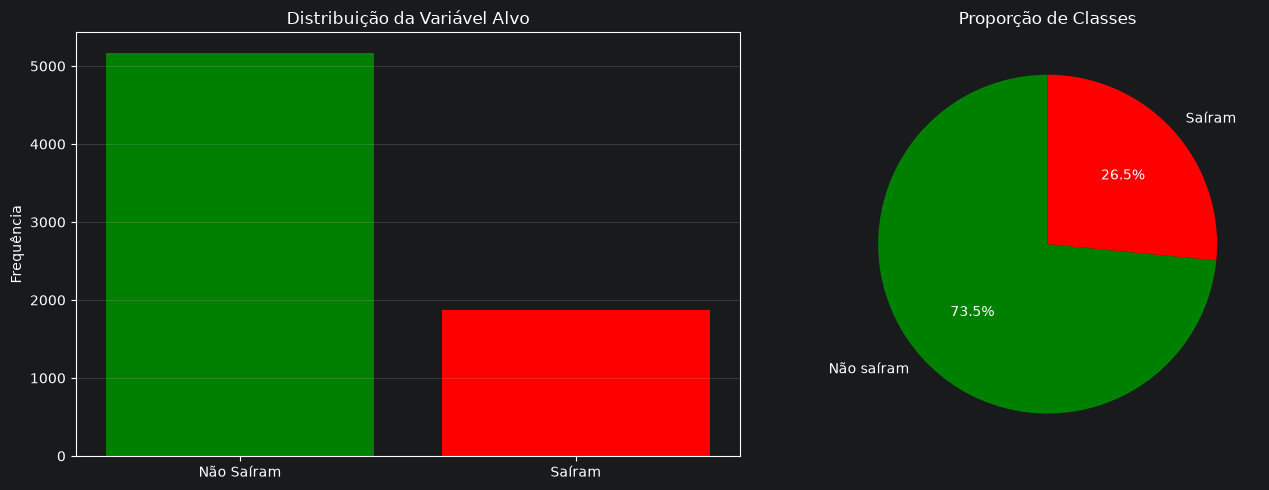


Ratio de balanceamento: 0.36
⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.


In [5]:
print("Distribuição da variável alvo")
contagem_alvo = df['target'].value_counts()
percentual_alvo = df['target'].value_counts(normalize=True) * 100

print("\nContagem: ", contagem_alvo)
print("\nPercentage: ", percentual_alvo)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].bar(['Não Saíram', 'Saíram'], contagem_alvo.values, color=['green', 'red'])
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Variável Alvo')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(contagem_alvo.values, labels=['Não saíram', 'Saíram'],
           autopct='%1.1f%%', colors=['green', 'red'], startangle=90)
axes[1].set_title('Proporção de Classes')
plt.tight_layout()
plt.show()

ratio = contagem_alvo.min() / contagem_alvo.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
   print("⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.")
else:
   print("✓ Dataset razoavelmente balanceado.")

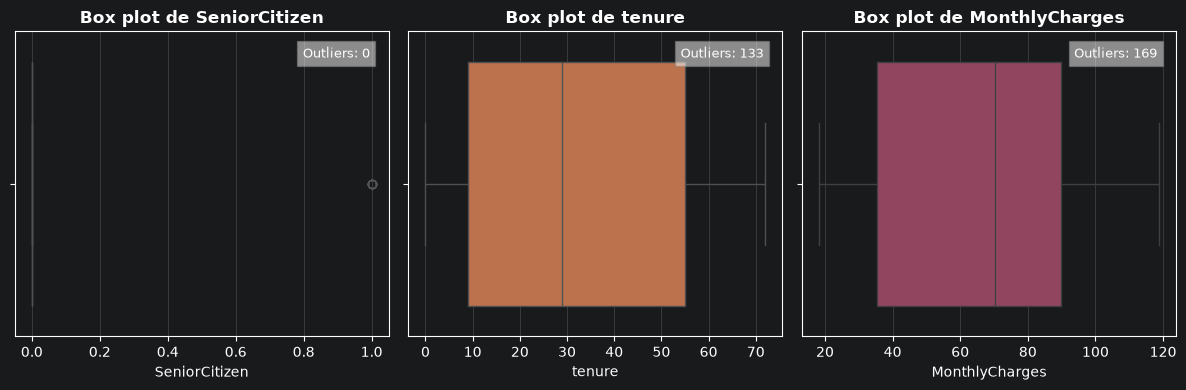

In [6]:
colunas_numericas = df.select_dtypes(include=[np.number]).columns
colunas_numericas = colunas_numericas.drop('target')

quantidade_colunas_numericas = len(colunas_numericas)
numero_colunas_plot = 3
numero_linhas_plot = int(np.ceil(quantidade_colunas_numericas / numero_colunas_plot))
figura, axes = plt.subplots(numero_linhas_plot, numero_colunas_plot , figsize=(12, 4 * numero_linhas_plot))
axes = axes.ravel()

for index, coluna in enumerate(colunas_numericas):
    sns.boxplot(x=df[coluna], ax=axes[index], color=sns.color_palette()[index])
    axes[index].set_title(f"Box plot de {coluna}", fontweight='bold')
    axes[index].set_xlabel(coluna)
    axes[index].grid(axis='x', alpha=0.3)
    coluna_zscore = np.abs(stats.zscore(df[coluna]))
    contagem_outlier = (coluna_zscore < 0.05).sum()
    axes[index].text(0.95, 0.95, f'Outliers: {contagem_outlier}',
                   transform=axes[index].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

for ax in axes[numero_colunas_plot:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()